## Présentation du projet CVRIE

CVRIE est une intelligence artificielle spécialisée dans le domaine médical, conçue pour assister les équipes hospitalières dans des tâches critiques. Elle doit être capable d'analyser des images médicales, de prendre en charge des patients et de poser des diagnostics avec précision. Notre mission est donc de développer CVRIE, une version suffisamment intelligente pour gérer deux tâches essentielles à l'hôpital. La première consiste à analyser les témoignages des patients à leur admission pour les regrouper par pathologie ou degré d'urgence. La seconde, qui constitue le cœur de la partie supervisée de notre projet, est d'analyser des images médicales et des scanners afin de formuler un diagnostic fiable.

In [1]:
import os
from PIL import Image
import pandas as pd
import seaborn as seaborn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC


## Vérification nombre d'images de chaque tumeur Training

Ce code permet d'afficher les types de tumeur différentes et le nombre d'images associés à chacune des tumeurs.

In [2]:
liste_tumeur = {}                                                   # On initialise un dictionnaire vide pour stocker chaque tumeurs et le nombre d'images associées

dossier = os.listdir("Dataset/Training")                            # C'est le dossier que l'on va parcourir pour trouver les différentes tumeurs

for k in dossier:                                                   # La boucle qui permet de parcours le dossier pour trouver les différents dossiers relatifs à chaque tumeur
    if k not in liste_tumeur:
        liste_tumeur[k] = 0                                         # On ajoute à la boucle que si elle n'est pas déjà présente dans le dictionnaire

print (f"Liste des différentes tumeurs : {liste_tumeur}") 

for j in liste_tumeur:                                              # On parcourt tout le dictionnaire qui vient d'être rempli 
    dossier_actuel = os.path.join("Dataset/Training", j)            # Les dossiers à parcourir sont donc les différents dossier de tumeurs
    for l in os.listdir(dossier_actuel):
        liste_tumeur[j] += 1                                        # On ajoute 1 à chaque image de chaque tumeurs

print (f"Nombre d'images de chaque tumeur : {liste_tumeur}") 

Liste des différentes tumeurs : {'notumor': 0, 'meningioma': 0, 'pituitary': 0, 'glioma': 0}
Nombre d'images de chaque tumeur : {'notumor': 1400, 'meningioma': 1400, 'pituitary': 1400, 'glioma': 1400}


## Graphique nombre d'image de chaque tumeur Training

On fait un graphique pour bien vérifier qu'il y a le même nombre d'images pour chaque tumeurs.

<Axes: xlabel='Type_Tumeur', ylabel='Count'>

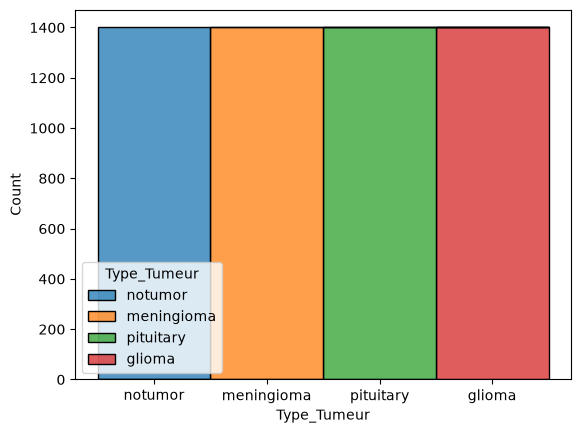

In [3]:
df = pd.DataFrame(list(liste_tumeur.items()), columns=['Type_Tumeur', 'Valeur'])                        # Pour faire un graphique, on transforme le dictionnaire en Dataframe
seaborn.histplot(data=df, x='Type_Tumeur', weights='Valeur', hue='Type_Tumeur', multiple='stack')       # Création du graphique

## Début préprocess (Récupération des infos des images)

Les images de chaque tumeurs ont des paramètres différents. Notre but est de les normaliser afin d'unifier la façon dont on va les traiter et les donner à l'IA pour l'entrainer.

On va d'abord ce concentrer sur récuperer toutes les images afin d'analyser quels pattern reviennent le plus pour nous permettre de modifier le moins d'images possible. On va donc regarder les dimensions les plus présentes, savoir si il y a plus d'image en noir et blanc ou en couleur et enfin le format de compression des images (PNG, JPEG ...)

In [4]:
df.head()                                                                   # class de df
df.info()                                                                   # infos du nombre d'entrée du df
df.describe()                                                               # Description df (nombre colonne / infos à l'interieur ...)

liste_taille = {}                                                           # On initialise 3 nouveeux dictionnaires pour les 3 vérifications
liste_format = {}
liste_couleur = {}

for j in liste_tumeur.keys():                                               # On va parcourir les différents dossier de tumeurs et regarder les images
    dossier_actuel = os.path.join("Dataset/Training", j)                   
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset/Training", j, l)             
        img = Image.open(fichier_actuel)
        if img.size not in liste_taille.keys():                             # Ajout des différentes dimensions des images
            liste_taille[img.size] = 1
        else:
            liste_taille[img.size] += 1
        if img.format not in liste_format.keys():                           # Ajout de différent format de compression d'image (PNG, JPEG ...)
            liste_format[img.format] = 1
        else:
            liste_format[img.format] += 1 
        if img.mode not in liste_couleur:                                   # Ajout des différent mode de colorimétrie des images (J, RGB, RGBA ...)
            liste_couleur[img.mode] = 1
        else:
            liste_couleur[img.mode] += 1

taille_max = max(liste_taille, key=liste_taille.get)                        # Dimensions les plus présentes
format_max = max(liste_format, key=liste_format.get)                        # Format le plus présent
couleur_max = max(liste_couleur, key=liste_couleur.get)                     # Couleur la plus présente
print("Type de dimensions : ", liste_taille)
print("Type de formats : ", liste_format)
print("Type de couleurs : ", liste_couleur)
print("Dimensions les plus présentes :", str(taille_max) + ". Nombre d'images avec ces dimensions :", liste_taille[taille_max])
print("Format le plus présent :", format_max + ". Nombre d'images avec ce format :", liste_format[format_max])
print("Couleur la plus présente :", couleur_max + ". Nombre d'images avec ce mode de colorimétrie :", liste_couleur[couleur_max])

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Type_Tumeur  4 non-null      str  
 1   Valeur       4 non-null      int64
dtypes: int64(1), str(1)
memory usage: 196.0 bytes
Type de dimensions :  {(235, 215): 1, (680, 680): 12, (225, 225): 253, (236, 300): 2, (228, 221): 32, (1024, 1024): 5, (194, 259): 8, (550, 664): 15, (350, 393): 6, (215, 234): 19, (150, 198): 33, (630, 630): 69, (236, 213): 17, (214, 236): 19, (512, 512): 4012, (206, 244): 26, (235, 214): 10, (350, 350): 11, (173, 201): 26, (177, 197): 6, (236, 240): 1, (207, 243): 11, (926, 649): 2, (359, 449): 16, (218, 231): 22, (442, 454): 13, (212, 238): 8, (236, 262): 2, (236, 236): 39, (204, 247): 1, (236, 357): 5, (201, 251): 40, (232, 217): 32, (300, 168): 8, (605, 613): 2, (196, 257): 11, (339, 340): 12, (205, 249): 2, (441, 442): 13, (230, 282): 15, (208, 248): 4, (442, 442): 38, (450, 504): 1, (

## Première conclusion

Tout d'abord, à la base, on à bien vérifier qu'il y a bien le <b>même nombre d'images</b> pour CHAQUE tumeur, et pour les images SANS tumeurs.

On peut le remarquer via les <b>première vérification</b> ainsi que le <u>graphique</u>. Nous avons en tout, <u>5600 images</u>, réparties en <b>4 catégories</b>, ce qui fait 1400 images par catégorie.

Ensuite, nous avons vérifier les <u>différents éléments</u> de chaques images. Comme leurs <b>dimensions</b>, leurs <b>formats</b> et leurs <b>colorimétries.</b>

On a pu voir que sur les <u>5600 images</u>, 4012 était en (512, 512) ce qui va très certainement devenir nos dimensions par défaut. <b>Cependant</b> il faudra faire attention, car certaines images ne sont pas des carrés. Signifiant qu'une conversion sans vérification pourrait applatir ou couper l'image. 

Ensuite, il y en a 5596 en <b>JPEG</b> et 4 en format <b>PNG</b>, bien que noté comme JPEG. Malgré que ces deux formats de compressions soient différents, nous ne trouvons pas cela dérangeant et <u>décidons de ne pas toucher à ces quatres images</u>. Les enlever serai complément contre-productif étant donné qu'elles reste exploitables comme les autres, et peuvent être comparées entre-elles sans difficultés.

Et enfin, leurs colorimétrie. Le plus courant est le <b>RGB</b> avec 3238 images, cependant, malgré qu'elle soit noté comme en <b>RGB</b>, un IRM n'utilise que des nuances de gris, signifiant que la transformation de toutes les images en mode <b>L (Lab / ou CIELLaB)</b> c'est à dire avec des nuances de gris sur une échelle de 0 à 100. 

Pour notre première étape de normalisation, nous décidons donc : 

- <u>De passer toutes les images en noir et blanc.
- De passer toutes les images en dimensions (128, 128)
- De laisser les images avec leurs modes car 99.9% sont en JPEG</u>

## Premier Preprocess

Maintenant que l'on sait vers quoi nous voulons transformer nos images, nous pouvons passer au preprocess.

On va tout d'abord vérifier leurs colorimétrie puis seulement leurs dimensions.

Pour la colorimétrie, c'est une simple convertion. Mais pour leurs dimensions, il a fallu distinguer les images carrés des autres. En effet, si un image est carré, alors une simple conversion fera l'affaire. Mais pour une image qui n'est pas carré, la rendre carré va la déformer. C'est pourquoi nous regardons si une image est carré ou non, et si elle ne l'est pas, alors nous la rapprochons le plus des dimensions voulu, puis nous ajoutons des padding pour compléter la taille de l'image.

In [ ]:
X_train = []
y_train = []

# Définition des chemins pour éviter les erreurs de frappe
chemin_source = "Dataset/Training"
chemin_cible = "Dataset_clean/Training"

for j in liste_tumeur.keys():
    dossier_actuel = os.path.join(chemin_source, j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join(chemin_source, j, l)
        Dossier_cible = os.path.join(chemin_cible, j)
        
        img = Image.open(fichier_actuel)
        
        # Conversion en niveaux de gris si nécessaire
        if img.mode not in ("L", "l"):
            img = img.convert('L')

        # Redimensionnement et padding pour arriver à 512x512
        if img.size != (128, 128):
            ratio = 128 / max(img.size)
            nouvelle_taille = (
                int(img.size[0] * ratio),
                int(img.size[1] * ratio)
            )
            img = img.resize(nouvelle_taille)

            nouvelle_img = Image.new("L", (128, 128))
            x = (128 - img.size[0]) // 2
            y = (128 - img.size[1]) // 2
            nouvelle_img.paste(img, (x, y))
            img = nouvelle_img

        # Sauvegarde de l'image nettoyée
        os.makedirs(Dossier_cible, exist_ok=True)
        img.save(os.path.join(Dossier_cible, l))
        
        # Préparation des données pour le modèle
        img_array = np.asarray(img, dtype=np.float16) / 255.0   # La normalisation permet d'avoir des valeurs numériques dans une échelle plus petite et homogène, ce qui est généralement plus pratique pour les algorithmes de Machine Learning.
        img_array = img_array.flatten()

        X_train.append(img_array)
        y_train.append(j)

## Vérification formats images

Après avoir tout transformer, on vérifie bien que les dimensions de toutes les images ont bien été transformé en (128, 128).

In [6]:
for j in liste_tumeur.keys():                                               # Vérification que toutes les images sont dans les mêmes formats (dimensions, colorimétrie)
    dossier_actuel = os.path.join("Dataset_clean/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset_clean/Training", j, l)
        img = Image.open(fichier_actuel)
        print 
        if img.size != (128, 128):
            print("MAUVAISES DIMENSIONS DETECTÉES")

## Vérification des doublons.

In [7]:
# for j in liste_tumeur.keys():
#     dossier_actuel = os.path.join("Dataset/Training", j)
#     fichiers = os.listdir(dossier_actuel)

#     for i in range(len(fichiers)):
#         for k in range(i + 1, len(fichiers)):
#             image_actuelle = os.path.join(dossier_actuel, fichiers[i])
#             image_suivante = os.path.join(dossier_actuel, fichiers[k])

#             img1 = Image.open(image_actuelle)
#             img2 = Image.open(image_suivante)
#     print("yeah")

## Vérification des dimensions

À la fin du preprocess, nous faisons un .flatten() qui "applati" les images qui transforme leurs dimensions (128,128) en (16384,) (128*128 = 16384 pixels)

In [8]:
X = np.array(X_train)
y = np.array(y_train)

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (5600, 16384)
Dimensions de y : (5600,)


## Modèle KNN

Mainteant que nos données ont été normalisées et vérifiées, nous allons les donner à l'IA pour l'entrainer, pour cela nous utilisons plusieurs modèles afin de trouver lequel est le plus précis.

Ici, nous faisons donc un KNN. Un KNN sert à classer des données ou à prédire une valeur numérique. Et c'est justement ce que l'on veut ici, on veut que notre IA soit capable de classer des images en différentes catégorie de tumeurs.

Le modèle KNN fonctionne de cette manière :

1) On regarde les données d'entraînement
2) On calcule leur distance par rapport à la nouvelle donnée
3) On sélectionne les K voisins les plus proches
4) On regarde leurs classes
5) On attribue une classe selon les voisins

In [9]:
# random state sert à rendre la séparation reproductible. Sans ça, chaque exécution pourrait produire une séparation différente.
# stratify permet d'éviter que le hasard créer une répartition moins équilibrée
X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train :", X_train_knn.shape)
print("X_test :", X_test_knn.shape)

X_train : (4480, 16384)
X_test : (1120, 16384)


In [10]:
meilleur = 0.0
meilleur_chiffre = 0

for k in range(1, 8, 2):                                        # On teste plusieurs nombre de voisins pour garder le plus efficace
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_knn)                           # On entraine le modèle avec tous les nombres de voisins.

    y_pred = knn.predict(X_test_knn)

    accuracy = accuracy_score(y_test_knn, y_pred)
    if accuracy > meilleur:                                     # On récupère le meilleur résultat pour prendre le meilleur knn
        meilleur = accuracy
        meilleur_chiffre = k
        meilleur_y_pred = y_pred
        bon_knn = knn
print(f"Meilleur résultat du KNN via n_neighbors = {meilleur_chiffre} :", meilleur)

Meilleur résultat du KNN via n_neighbors = 1 : 0.9125


### Loss fonction

La fonction de perte est une mesure fondamentale en apprentissage supervisé qui évalue l'écart entre les prédictions de notre modèle et les valeurs réelles. On peut la voir comme un indicateur de performance qui calcule l'erreur commise à chaque étape de l'entraînement. Plus cette valeur est élevée, plus le modèle se trompe, et inversement.
Son rôle principal est de guider l'optimisation du modèle. Pendant l'apprentissage, l'algorithme ajuste continuellement ses paramètres internes dans le but précis de minimiser cette valeur. C'est un peu comme si le modèle essayait de descendre une pente pour trouver le point le plus bas, qui correspond à l'erreur la plus faible possible.
Dans notre projet de classification d'images, nous utilisons souvent des fonctions spécifiques comme la cross entropie. Cette fonction pénalise fortement le modèle lorsqu'il est très confiant dans une mauvaise prédiction, par exemple s'il identifie un méningiome comme un gliome avec une forte certitude. En minimisant constamment cette erreur, la fonction de perte permet au modèle d'apprendre et d'améliorer ses prédictions sur de nouvelles données.

## Matrice de confusion

Afin de voir les résultat de l'IA, pour par exemple voir les différentes erreurs qu'il à pu avoir, nous faison une matrice de confusion. Elle permet de voir la différence entre les résultat qu'il a prédit et les résultats réels.

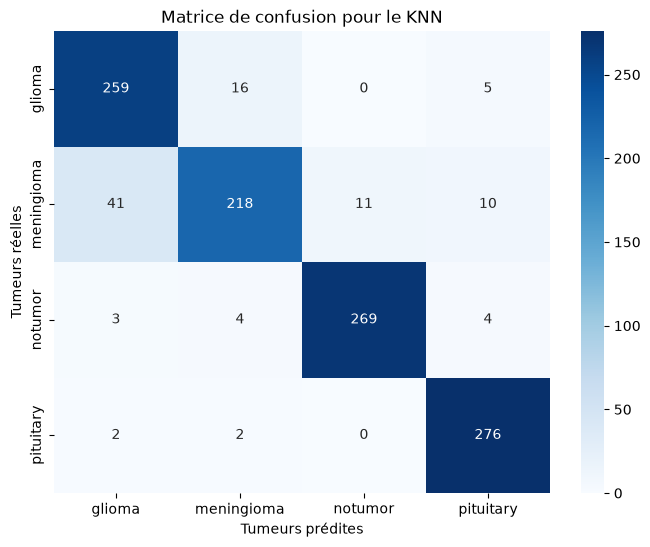

In [11]:
cm = confusion_matrix(y_test_knn, meilleur_y_pred)

plt.figure(figsize=(8, 6))

seaborn.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=bon_knn.classes_, yticklabels=bon_knn.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion pour le KNN")

plt.show()

## Random Forest

Ici, le Random Forest sert à faire des prédictions précises et robustes en combinant plusieurs arbres de décision. Un peu à l'instar du KNN, ce modèle essaye de prédire les catégorie de tumeurs à laquelle les images appartiennent.

In [18]:
# random state sert à rendre la séparation reproductible. Sans ça, chaque exécution pourrait produire une séparation différente.
# n_jobs = -1 permet d'utiliser tous les cœurs CPU disponibles pour les opérations parallélisables.
max_accuracy = 0
bon_n_estimators = 0

for k in range(10, 150, 20):

    randomforest = RandomForestClassifier(n_estimators=k, random_state=42, n_jobs=-1) 

    randomforest.fit(X_train_knn, y_train_knn)

    y_pred = randomforest.predict(X_test_knn)

    accuracy = accuracy_score(y_test_knn, y_pred)

    if accuracy > max_accuracy:
        max_accuracy = accuracy
        bon_n_estimators = k
        bon_y_pred = y_pred
        bon_randomforest = randomforest
    print("Résultat du RandomForestClassifier", k, ":", accuracy)

Résultat du RandomForestClassifier 10 : 0.8928571428571429
Résultat du RandomForestClassifier 30 : 0.9071428571428571
Résultat du RandomForestClassifier 50 : 0.9151785714285714
Résultat du RandomForestClassifier 70 : 0.9151785714285714
Résultat du RandomForestClassifier 90 : 0.9151785714285714
Résultat du RandomForestClassifier 110 : 0.9142857142857143
Résultat du RandomForestClassifier 130 : 0.9151785714285714


## Matrice de confusion

Comme pour le KNN, nous avons fait une matrice de confusion afin de voir les résultats de l'IA. voir les endroits où il a pu se tromper entre ce qu'il à prédit et le véritable résultat.

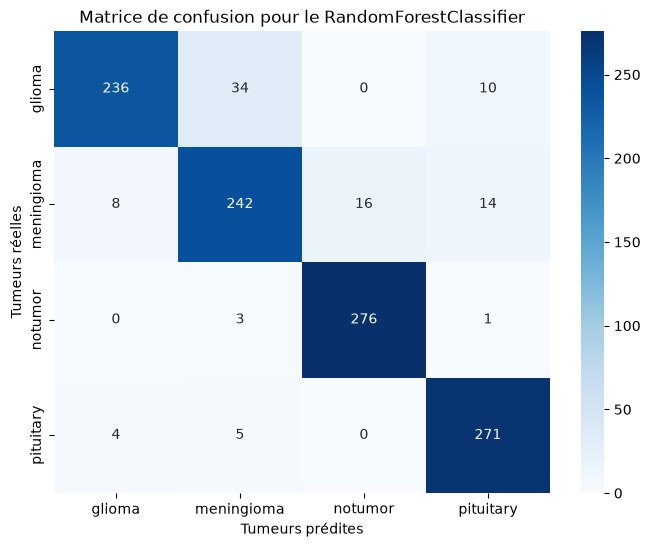

In [19]:
cm = confusion_matrix(y_test_knn, bon_y_pred)

plt.figure(figsize=(8, 6))

seaborn.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=bon_randomforest.classes_, yticklabels=bon_randomforest.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion pour le RandomForestClassifier")

plt.show()

### SVM Modele


Précision du SVM : 0.8625


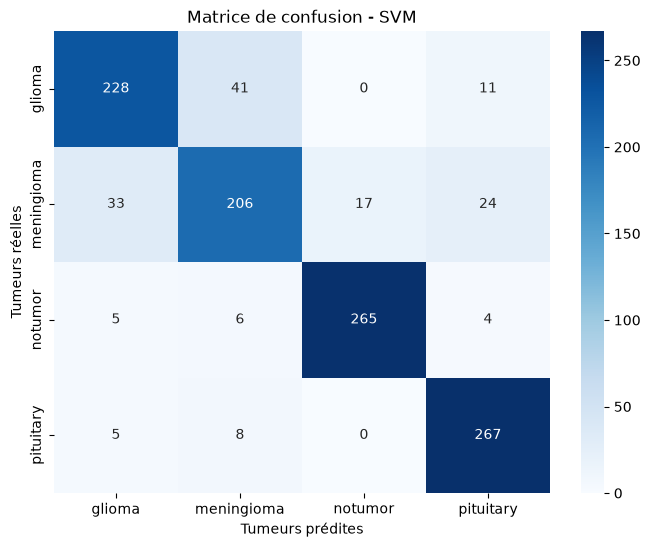

In [20]:
modele_svm = SVC(random_state=42)

modele_svm.fit(X_train_knn, y_train_knn)
predictions = modele_svm.predict(X_test_knn)
precision = accuracy_score(y_test_knn, predictions)

print(f"Précision du SVM : {precision:.4f}")
matrice_confusion = confusion_matrix(y_test_knn, predictions)

plt.figure(figsize=(8, 6))
seaborn.heatmap(matrice_confusion, annot=True, fmt="d", cmap="Blues", xticklabels=modele_svm.classes_, yticklabels=modele_svm.classes_)
plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion - SVM")
plt.show()


## Modèle LogisticRegression



Aussi, encore une fois, nous avons fait une matrice de confusion afin de voir les résultats de l'IA. voir les endroits où il a pu se tromper entre ce qu'il à prédit et le véritable résultat.

Précision de la régression logistique : 0.8491


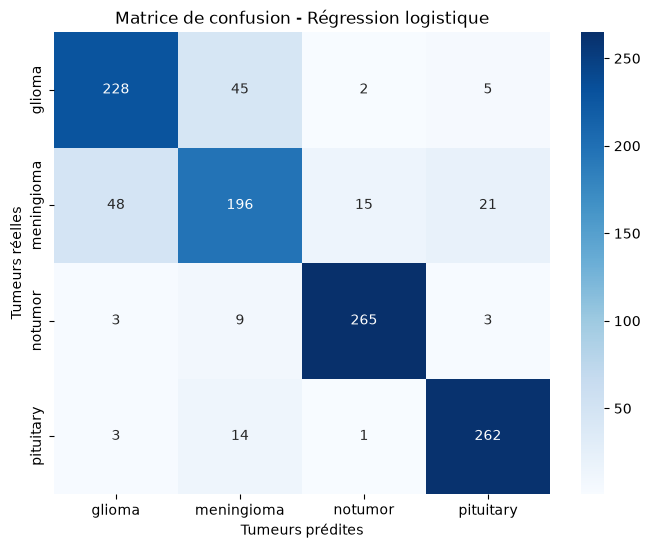

In [15]:
from sklearn.linear_model import LogisticRegression

modele_logreg = LogisticRegression(max_iter=1000, random_state=42)
modele_logreg.fit(X_train_knn, y_train_knn)
predictions = modele_logreg.predict(X_test_knn)
precision = accuracy_score(y_test_knn, predictions)

print(f"Précision de la régression logistique : {precision:.4f}")
matrice_confusion = confusion_matrix(y_test_knn, predictions)

plt.figure(figsize=(8, 6))
seaborn.heatmap(matrice_confusion, annot=True, fmt="d", cmap="Blues", xticklabels=modele_logreg.classes_, yticklabels=modele_logreg.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion - Régression logistique")
plt.show()


### Comparaison des modèles

Maintenant que les quatre modèles ont été entraînés, on peut comparer leurs performances sur les mêmes données de test. Cela permet de voir lequel obtient les meilleurs résultats sur notre jeu de données.

Comparaison des modèles
Accuracy : 0.9125
              precision    recall  f1-score   support

      glioma       0.85      0.93      0.89       280
  meningioma       0.91      0.78      0.84       280
     notumor       0.96      0.96      0.96       280
   pituitary       0.94      0.99      0.96       280

    accuracy                           0.91      1120
   macro avg       0.91      0.91      0.91      1120
weighted avg       0.91      0.91      0.91      1120

Accuracy : 0.9152
              precision    recall  f1-score   support

      glioma       0.95      0.84      0.89       280
  meningioma       0.85      0.86      0.86       280
     notumor       0.95      0.99      0.97       280
   pituitary       0.92      0.97      0.94       280

    accuracy                           0.92      1120
   macro avg       0.92      0.92      0.91      1120
weighted avg       0.92      0.92      0.91      1120

Accuracy : 0.8625
              precision    recall  f1-score   suppor

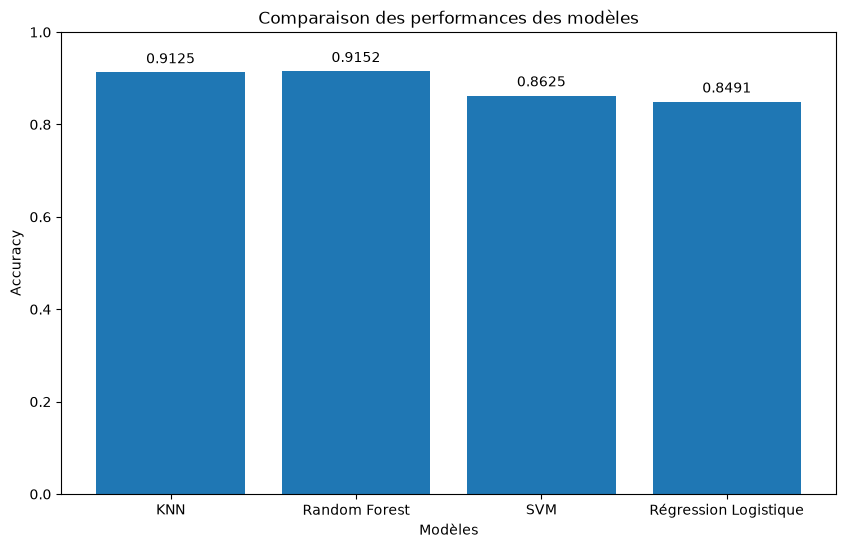

Resultats de la comparaison
Le modèle avec la plus grande accuracy dans ce test est : Random Forest (0.9152)


In [17]:
from sklearn.metrics import classification_report

modeles = {"KNN": bon_knn, "Random Forest": bon_randomforest, "SVM": modele_svm, "Régression Logistique": modele_logreg}
resultats = {}

print("Comparaison des modèles")

for nom, modele in modeles.items():
    predictions = modele.predict(X_test_knn)
    accuracy = accuracy_score(y_test_knn, predictions)
    resultats[nom] = accuracy
    print(f"Accuracy : {accuracy:.4f}")
    print(classification_report(y_test_knn, predictions))


# Matrice de confusion pour chaque modèle
print("Performance des modèles :")

for nom, accuracy in resultats.items():
    print(f"{nom:<25} : {accuracy:.4f}")


# Comparaison des modèles
plt.figure(figsize=(10, 6))
plt.bar(resultats.keys(), resultats.values())

plt.xlabel("Modèles")
plt.ylabel("Accuracy")
plt.title("Comparaison des performances des modèles")
plt.ylim(0, 1)

# Affichage de la valeur au-dessus de chaque barre
for i, (nom, accuracy) in enumerate(resultats.items()):
    plt.text(i, accuracy + 0.02, f"{accuracy:.4f}", ha="center")
plt.show()


# modèle avec + d'accuracy
meilleur_modele = max(resultats, key=resultats.get)

print("Resultats de la comparaison")
print(f"Le modèle avec la plus grande accuracy dans ce test est : "f"{meilleur_modele} ({resultats[meilleur_modele]:.4f})")

## Conclusion et Insights – Partie Supervisée

### Performances des modèles
Au terme de cette partie supervisée, on a pu tirer plusieurs enseignements intéressants sur le comportement de nos modèles. Le Random forest s'impose clairement comme le champion avec une précision de 90,89%. C'est un résultat très solide, surtout comparé aux autres approches. Le KNN suit de très près à 90,63%, ce qui montre que parfois les méthodes simples fonctionnent super bien sur ce type de données.

### Limites observées
Ce qui nous a surpris par contre, c'est la contre-performance des modèles linéaires. La régression logistique à 83% et le SVM à 85,6% peinent à suivre. En regardant les matrices de confusion, on a vite compris pourquoi. Ces modèles galèrent surtout avec les méningiomes qu'ils confondent souvent avec les gliomes. C'est tout à fait logique car visuellement, ces deux types de tumeurs se ressemblent pas mal, surtout après avoir aplati nos images.

### Limitation technique majeure
Cela met en lumière une limitation importante de notre approche actuelle. On a complètement détruit la structure spatiale des images en les convertissant en tableaux plats de 16 384 features. Pour des modèles comme la régression logistique ou le SVM qui ne comprennent pas les relations entre pixels voisins, c'est un vrai handicap.

### Bilan et perspectives
Au final, 91% de précision c'est pas mal du tout pour une première approche, mais on est convaincus qu'on peut faire beaucoup mieux avec les bonnes architectures.